# Monte Carlo Option Pricing Engine

## 1. Introduction & Assumptions

The goal of this project is to build a reusable Monte Carlo pricing engine under risk-neutral GBM for European, Asian, barrier and American options, and validate it against Black-Scholes.

**Model.** The stock price follows risk-neutral geometric Brownian motion with no dividends:

$$dS_t = r\,S_t\,dt + \sigma\,S_t\,dW_t$$

**Assumptions**
| Item | Choice | Reason |
|---|---|---|
| Trading days per year | 252 | Project specification |
| Time step | Half a day if expiry is under 30 days, otherwise one day | Project specification |
| Path matrix | Does not include $S_0$ | Column 0 is the price after the first step |
| Asian average | Arithmetic average of the simulated prices | Standard contract definition |
| Barrier touch | Up: $S \ge B$; down: $S \le B$; checked at every simulated step | Discrete monitoring (studied in Section 10) |
| Knock-in payoff | European payoff once the barrier has been touched | Standard definition |
| American exercise | Allowed at every simulated step | Same grid as the simulation |
| LSM regression | In-the-money paths only; constant, $S$ and $S^2$ | Longstaff and Schwartz (2001) |
| Random seed | 42 | Reproducible results |

**Standard test inputs** (used throughout): $S_0 = 100$, $K = 100$, expiry 252 trading days (1 year), $r = 5\%$, $\sigma = 20\%$, 100,000 paths.

## 2. Imports & Parameters

All pricing functions are in `src/pricer.py`. The notebook only calls them and checks the results. The parameters below are the standard test inputs used in every section.

In [1]:
%reload_ext autoreload
%autoreload 2
import sys
sys.path.append('..')

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.pricer import *


#Parameters below
S0 = 100
K = 100
expiry_days = 252
r = 0.05
sigma = 0.20
n_simulations = 100000
seed = 42

## 3. Time Grid & GBM Paths

**Purpose.** Build the time grid and simulate the stock-price paths on which every option in this notebook is priced.

**Time grid.** A year has 252 trading days. Options with less than 30 days to expiry use half-day steps; longer ones use daily steps.

**Path simulation.** Each step multiplies the price by a random factor:

$$S_{t+\Delta t} = S_t \exp\!\left[\left(r - \tfrac{1}{2}\sigma^2\right)\Delta t + \sigma\sqrt{\Delta t}\;Z\right], \qquad Z \sim N(0,1)$$

All paths are simulated at once as a matrix (one row per path, one column per time step), with no loop over paths.

In [2]:
for days in [1, 5, 10, 20, 30, 60, 120, 252]:
    dt, n_steps, T = get_time_grid(days)
    print(f"Expiry days: {days}, dt: {dt}, n_steps: {n_steps}, T: {T}")

Expiry days: 1, dt: 0.001984126984126984, n_steps: 2, T: 0.003968253968253968
Expiry days: 5, dt: 0.001984126984126984, n_steps: 10, T: 0.01984126984126984
Expiry days: 10, dt: 0.001984126984126984, n_steps: 20, T: 0.03968253968253968
Expiry days: 20, dt: 0.001984126984126984, n_steps: 40, T: 0.07936507936507936
Expiry days: 30, dt: 0.003968253968253968, n_steps: 30, T: 0.11904761904761904
Expiry days: 60, dt: 0.003968253968253968, n_steps: 60, T: 0.23809523809523808
Expiry days: 120, dt: 0.003968253968253968, n_steps: 120, T: 0.47619047619047616
Expiry days: 252, dt: 0.003968253968253968, n_steps: 252, T: 1.0


**Reading the output.** `dt` is the step length in years, `n_steps` the number of steps and `T` the time to expiry in years. A 20-day option has 40 half-day steps; a 252-day option has 252 daily steps and $T = 1$.

In [3]:
start = time.perf_counter()
paths = simulate_gbm_paths(S0, r, sigma, expiry_days, n_simulations, seed=seed)
elapsed = time.perf_counter() - start

dt, n_steps, T = get_time_grid(expiry_days)

print("Shape of paths:", paths.shape)
print(f"Mean of S_T      = {paths[:, -1].mean():.4f}")
print(f"Theory S0*e^(rT) = {S0 * np.exp(r * T):.4f}")
print("Same seed gives identical paths:",
      np.array_equal(paths, simulate_gbm_paths(S0, r, sigma, expiry_days, n_simulations, seed=seed)))
print(f"Simulation time: {elapsed:.2f} seconds")

Shape of paths: (100000, 252)
Mean of S_T      = 105.1672
Theory S0*e^(rT) = 105.1271
Same seed gives identical paths: True
Simulation time: 0.52 seconds


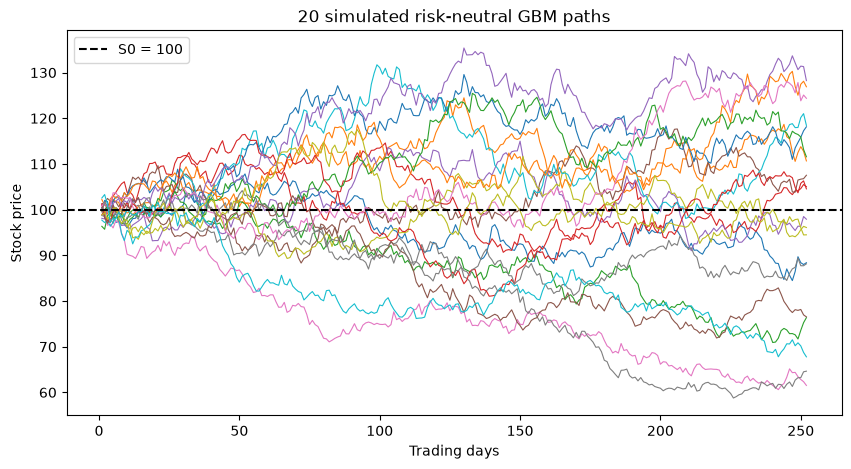

In [4]:
time_in_days = np.arange(1, n_steps + 1) * dt * TRADING_DAYS   # 横轴：第 1 天 ~ 第 252 天

plt.figure(figsize=(10, 5))
plt.plot(time_in_days, paths[:20].T, linewidth=0.8)            # 只画前 20 条
plt.axhline(S0, color="black", linestyle="--", label="S0 = 100")
plt.xlabel("Trading days")
plt.ylabel("Stock price")
plt.title("20 simulated risk-neutral GBM paths")
plt.legend()
plt.savefig("../outputs/01_gbm_paths.png", dpi=150, bbox_inches="tight")
plt.show()

### Interpretation

- **Shape:** 100,000 paths × 252 steps, as intended.
- **The drift is right:** the average final price is 105.17, against the theoretical $S_0 e^{rT}$ = 105.13, a difference of 0.04%. This confirms the $-\tfrac{1}{2}\sigma^2$ term; without it the average would be too high.
- **Reproducible:** the same seed gives exactly the same paths, so every number in this notebook can be reproduced.
- **Fast:** simulating about 25 million prices takes well under a second, because the calculation is vectorised.
- The chart shows 20 of the paths. They start near 100 and spread out over time; this spread is what gives options their value.

## 4. European Options vs Black-Scholes

**Purpose.** Price European calls and puts by simulation and compare them with the Black-Scholes formula. This is the key test of the engine: if it fails here, nothing later can be trusted.

$$\text{price} = e^{-rT} \times \text{average payoff}, \qquad \text{standard error} = \frac{s}{\sqrt{N}}$$

where $s$ is the standard deviation of the discounted payoffs and $N$ is the number of paths. The 95% confidence interval is the price ± 1.96 standard errors. Black-Scholes is used only as a benchmark.

In [5]:
dt, n_steps, T = get_time_grid(expiry_days)

bs_call = black_scholes(S0, K, T, r, sigma, "call")
bs_put = black_scholes(S0, K, T, r, sigma, "put")
print(f"Black-Scholes call = {bs_call:.4f}")
print(f"Black-Scholes put  = {bs_put:.4f}")

Black-Scholes call = 10.4506
Black-Scholes put  = 5.5735


In [6]:
discount = np.exp(-r * T)                                     # 折现因子 e^{-rT}

call_payoffs = european_payoff(paths, K, "call") * discount   # 每条路径折现后的 payoff
put_payoffs = european_payoff(paths, K, "put") * discount

mc_call = mc_summary(call_payoffs)
mc_put = mc_summary(put_payoffs)

print(f"MC call = {mc_call['price']:.4f}  (SE {mc_call['std_error']:.4f}, "
      f"95% CI [{mc_call['ci_low']:.4f}, {mc_call['ci_high']:.4f}])   BS = {bs_call:.4f}")
print(f"MC put  = {mc_put['price']:.4f}  (SE {mc_put['std_error']:.4f}, "
      f"95% CI [{mc_put['ci_low']:.4f}, {mc_put['ci_high']:.4f}])   BS = {bs_put:.4f}")

MC call = 10.4829  (SE 0.0469, 95% CI [10.3909, 10.5748])   BS = 10.4506
MC put  = 5.5676  (SE 0.0274, 95% CI [5.5140, 5.6213])   BS = 5.5735


**Result.** The Monte Carlo call is 10.48 against a Black-Scholes value of 10.45, and the put is 5.57 against 5.57. Both Black-Scholes prices lie inside the 95% confidence intervals, so the differences are consistent with simulation noise.

In [7]:
lhs = mc_call["price"] - mc_put["price"]
rhs = S0 - K * np.exp(-r * T)
print(f"MC:     C - P          = {lhs:.4f}")
print(f"Theory: S0 - K*e^(-rT) = {rhs:.4f}")

MC:     C - P          = 4.9152
Theory: S0 - K*e^(-rT) = 4.8771


**Put-call parity.** Theory says $C - P = S_0 - K e^{-rT}$ = 4.877. The simulation gives 4.915, a gap of 0.038.

The gap is not a bug. On every path, the call payoff minus the put payoff equals $S_T - K$, so the simulated $C - P$ is simply the discounted average of $S_T$ minus $K e^{-rT}$. The average $S_T$ was 0.040 too high (Section 3), and 0.040 discounted for one year is 0.038.

In [8]:
rows = []
for K_test in [80, 90, 100, 110, 120]:
    mc = mc_summary(european_payoff(paths, K_test, "call") * discount)
    bs = black_scholes(S0, K_test, T, r, sigma, "call")
    rows.append({
        "Strike K": K_test,
        "MC price": mc["price"],
        "CI low": mc["ci_low"],
        "CI high": mc["ci_high"],
        "BS price": bs,
        "Error": mc["price"] - bs,
        "BS inside CI": mc["ci_low"] <= bs <= mc["ci_high"],
    })

european_table = pd.DataFrame(rows).round(4)
european_table

,Strike K,MC price,CI low,CI high,BS price,Error,BS inside CI
0,80,24.6267,24.5074,24.7460,24.5888,0.0378,True
1,90,16.7380,16.6297,16.8464,16.6994,0.0386,True
2,100,10.4829,10.3909,10.5748,10.4506,0.0323,True
3,110,6.0703,5.9974,6.1432,6.0401,0.0302,True
4,120,3.2820,3.2273,3.3366,3.2475,0.0345,True


**Across strikes.** For all five strikes the Black-Scholes price is inside the confidence interval. The errors are all positive and similar in size (0.03–0.04) because every strike is priced on the same paths, whose average final price is slightly high.

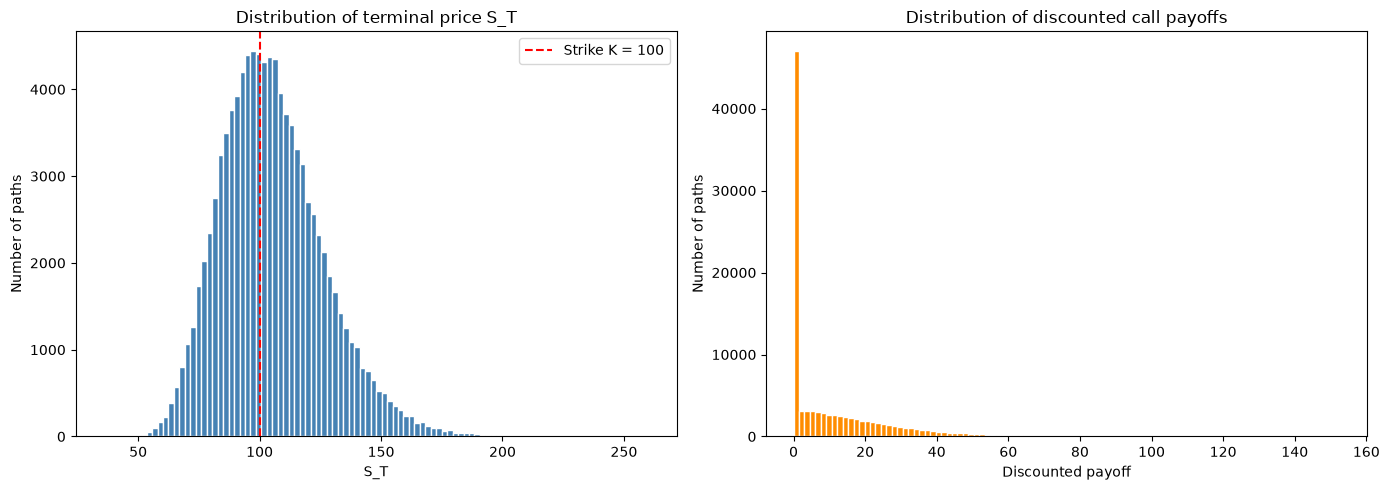

Share of paths where the call expires worthless: 44.0%


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(paths[:, -1], bins=100, color="steelblue", edgecolor="white")
axes[0].axvline(K, color="red", linestyle="--", label=f"Strike K = {K}")
axes[0].set_title("Distribution of terminal price S_T")
axes[0].set_xlabel("S_T")
axes[0].set_ylabel("Number of paths")
axes[0].legend()

axes[1].hist(call_payoffs, bins=100, color="darkorange", edgecolor="white")
axes[1].set_title("Distribution of discounted call payoffs")
axes[1].set_xlabel("Discounted payoff")
axes[1].set_ylabel("Number of paths")

plt.tight_layout()
plt.savefig("../outputs/02_payoff_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Share of paths where the call expires worthless: {(call_payoffs == 0).mean():.1%}")

### Interpretation

- **The engine reproduces Black-Scholes:** to within 0.3% for the call and 0.1% for the put.
- **Payoffs are very uneven.** In 44% of the paths the call expires worthless (the spike at zero), and a small number of paths pay a lot. The average is driven by relatively few large payoffs, which is why many paths are needed.

> **Takeaway:** the simulation, the discounting and the error estimate all work. The later sections change only the payoff, not the paths.

## 5. Asian Options

**Purpose.** Price Asian options, whose payoff depends on the **average** price along the path instead of the final price: the call pays $\max(\text{average} - K,\, 0)$. The arithmetic average of the simulated prices is used. No new simulation is needed: the same paths are reused with a different payoff.

In [10]:
asian_call = mc_summary(asian_payoff(paths, K, "call") * discount)
asian_put = mc_summary(asian_payoff(paths, K, "put") * discount)

print(f"Asian call    = {asian_call['price']:.4f}  (SE {asian_call['std_error']:.4f})")
print(f"European call = {mc_call['price']:.4f}")
print(f"Asian put     = {asian_put['price']:.4f}  (SE {asian_put['std_error']:.4f})")
print(f"European put  = {mc_put['price']:.4f}")

Asian call    = 5.7932  (SE 0.0254)
European call = 10.4829
Asian put     = 3.3604  (SE 0.0167)
European put  = 5.5676


### Interpretation

- **Asian options are much cheaper:** the Asian call is 5.79 against 10.48 for the European call (45% cheaper), and the Asian put is 3.36 against 5.57 (40% cheaper).
- **Why:** the average of a path moves much less than its end point. An option's value comes from volatility, so a less volatile underlying means a cheaper option.

> **Takeaway:** averaging lowers both the risk and the price. Asian options have no simple exact formula for the arithmetic average, which is exactly the kind of product Monte Carlo is useful for.

## 6. Barrier Options

**Purpose.** Price barrier options: European options that are switched on or off if the price touches a barrier level during the option's life.

- **Knock-out:** pays the European payoff only if the barrier was **never** touched.
- **Knock-in:** pays the European payoff only if the barrier **was** touched.

Every path has either touched the barrier or not, so

$$\text{knock-in} + \text{knock-out} = \text{European}$$

(in-out parity), which gives an exact check. The barrier is checked at each simulated step, which is once a day here.

In [11]:
parity_rows = []
for barrier, direction in [(120, "up"), (90, "down")]:
    knock_in = mc_summary(barrier_payoff(paths, K, barrier, f"{direction}-and-in", "call") * discount)
    knock_out = mc_summary(barrier_payoff(paths, K, barrier, f"{direction}-and-out", "call") * discount)
    parity_rows.append({
        "Barrier": barrier,
        "Type": direction,
        "Knock-in": knock_in["price"],
        "Knock-out": knock_out["price"],
        "In + Out": knock_in["price"] + knock_out["price"],
        "European": mc_call["price"],
    })

barrier_parity_table = pd.DataFrame(parity_rows).round(4)
barrier_parity_table

,Barrier,Type,Knock-in,Knock-out,In + Out,European
0,120,up,9.1635,1.3193,10.4829,10.4829
1,90,down,1.5194,8.9635,10.4829,10.4829


**Reading the table.** In-out parity holds exactly for both barriers.

- With an **up** barrier at 120, almost all of the call's value is in the knock-in (9.16 of 10.48). A call pays most when the price rises a lot, and those are the paths that touch 120. The up-and-out call is worth only 1.32, because it pays only if the price ends above 100 without ever reaching 120.
- With a **down** barrier at 90 it is the other way round: the knock-out keeps most of the value (8.96).

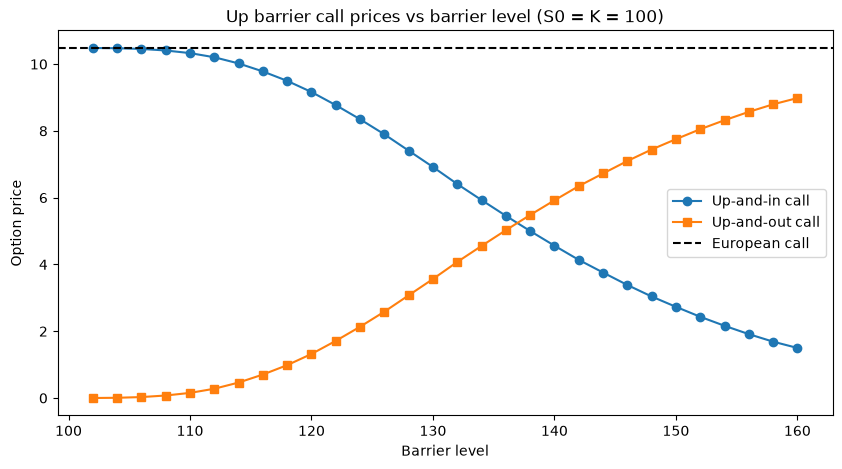

In [12]:
barrier_levels = np.arange(102, 162, 2)       # 102, 104, ..., 160

up_in_prices = [np.mean(barrier_payoff(paths, K, B, "up-and-in", "call")) * discount for B in barrier_levels]
up_out_prices = [np.mean(barrier_payoff(paths, K, B, "up-and-out", "call")) * discount for B in barrier_levels]

plt.figure(figsize=(10, 5))
plt.plot(barrier_levels, up_in_prices, "o-", label="Up-and-in call")
plt.plot(barrier_levels, up_out_prices, "s-", label="Up-and-out call")
plt.axhline(mc_call["price"], color="black", linestyle="--", label="European call")
plt.xlabel("Barrier level")
plt.ylabel("Option price")
plt.title("Up barrier call prices vs barrier level (S0 = K = 100)")
plt.legend()
plt.savefig("../outputs/03_barrier_levels.png", dpi=150, bbox_inches="tight")
plt.show()

### Interpretation

- As the barrier moves further above the current price, it is touched less often: the up-and-out price rises towards the European price and the up-and-in price falls towards zero. The two always add up to the European price.
- A barrier close to the current price changes the option's value dramatically.
- **Caveat:** the simulation only checks the barrier at its time steps, while a real barrier is usually monitored continuously. Section 10 measures how much this matters.

> **Takeaway:** a barrier makes an option cheaper by removing some of the paths that would have paid. How much cheaper depends strongly on where the barrier is.

## 7. Convergence & Antithetic Variates

**Purpose.** Measure how quickly the simulation error falls as paths are added, and test a variance-reduction technique.

- The standard error is $s/\sqrt{N}$, so it falls with the square root of the number of paths.
- **Antithetic variates:** every random draw $Z$ is paired with $-Z$. The two paths in a pair move in opposite directions, so their errors partly cancel. Each pair is averaged first, and the standard error is computed from the pair averages, because the two paths in a pair are not independent.

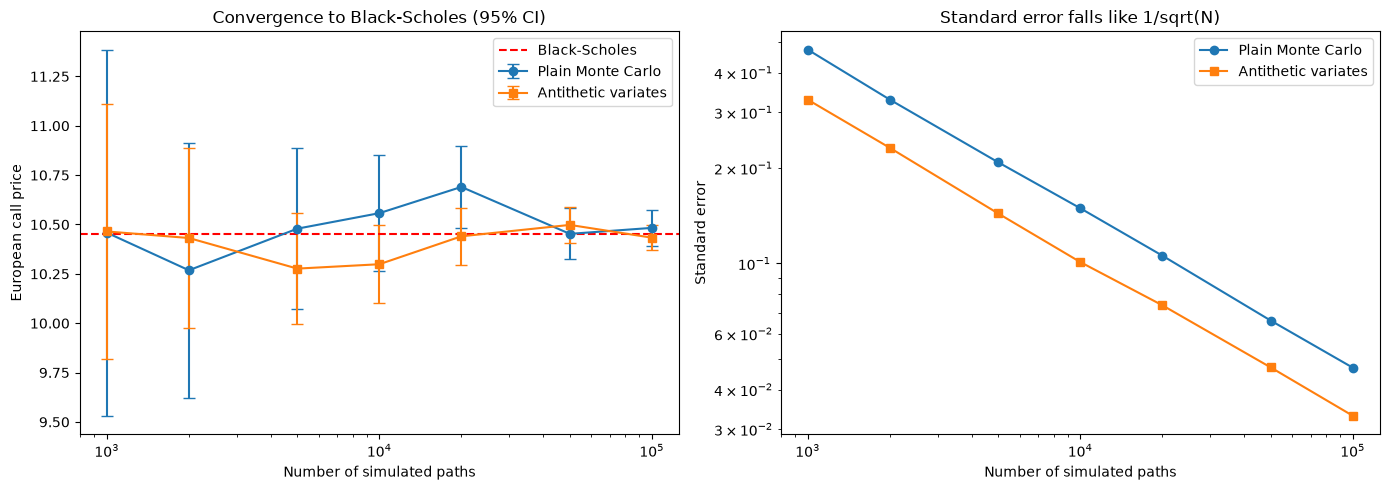

In [13]:
n_list = [1_000, 2_000, 5_000, 10_000, 20_000, 50_000, 100_000]

plain = [price_option(S0, K, expiry_days, r, sigma, "call", n_simulations=n, seed=seed) for n in n_list]
anti = [price_option(S0, K, expiry_days, r, sigma, "call", n_simulations=n, seed=seed, antithetic=True) for n in n_list]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].errorbar(n_list, [p["price"] for p in plain], yerr=[1.96 * p["std_error"] for p in plain],
                 fmt="o-", capsize=4, label="Plain Monte Carlo")
axes[0].errorbar(n_list, [a["price"] for a in anti], yerr=[1.96 * a["std_error"] for a in anti],
                 fmt="s-", capsize=4, label="Antithetic variates")
axes[0].axhline(bs_call, color="red", linestyle="--", label="Black-Scholes")
axes[0].set_xscale("log")
axes[0].set_xlabel("Number of simulated paths")
axes[0].set_ylabel("European call price")
axes[0].set_title("Convergence to Black-Scholes (95% CI)")
axes[0].legend()

axes[1].loglog(n_list, [p["std_error"] for p in plain], "o-", label="Plain Monte Carlo")
axes[1].loglog(n_list, [a["std_error"] for a in anti], "s-", label="Antithetic variates")
axes[1].set_xlabel("Number of simulated paths")
axes[1].set_ylabel("Standard error")
axes[1].set_title("Standard error falls like 1/sqrt(N)")
axes[1].legend()

plt.tight_layout()
plt.savefig("../outputs/04_convergence.png", dpi=150, bbox_inches="tight")
plt.show()

In [14]:
se_25k = price_option(S0, K, expiry_days, r, sigma, "call", n_simulations=25_000, seed=seed)["std_error"]
se_100k = plain[-1]["std_error"]
se_anti = anti[-1]["std_error"]

print(f"SE with  25,000 paths = {se_25k:.4f}")
print(f"SE with 100,000 paths = {se_100k:.4f}   (4x paths -> SE / {se_25k / se_100k:.2f})")
print(f"SE with antithetic    = {se_anti:.4f}   ({1 - se_anti / se_100k:.0%} lower than plain)")
print(f"Paths saved by antithetic for the same accuracy: {1 - (se_anti / se_100k)**2:.0%}")

start = time.perf_counter()
price_option(S0, K, expiry_days, r, sigma, "call", n_simulations=100_000, seed=seed)
print(f"Time to price one option with 100,000 paths: {time.perf_counter() - start:.2f} s")

SE with  25,000 paths = 0.0945
SE with 100,000 paths = 0.0469   (4x paths -> SE / 2.02)
SE with antithetic    = 0.0331   (29% lower than plain)
Paths saved by antithetic for the same accuracy: 50%
Time to price one option with 100,000 paths: 0.53 s


### Interpretation

- **Convergence:** as paths are added, the estimates settle around the Black-Scholes price and the confidence intervals narrow.
- **Convergence is slow:** four times as many paths (25,000 → 100,000) only halves the standard error (0.0945 → 0.0469). On the log-log chart the standard error is a straight line with slope $-\tfrac{1}{2}$.
- **Antithetic variates** lower the standard error by 29% (0.0469 → 0.0331) for the same number of paths. That is equivalent to using about twice as many paths.
- **Cost:** about half a second for 100,000 paths.

> **Takeaway:** with 100,000 paths the call price is accurate to about ±0.09 (95%), under 1% of its value. Halving that error needs four times the paths, or antithetic variates.

## 8. American Options (Longstaff-Schwartz)

**Purpose.** Price American options, which can be exercised at any time before expiry.

A simulation runs forwards in time, but the decision to exercise depends on the value of waiting, which depends on the future. The **Longstaff-Schwartz** method (least-squares Monte Carlo) solves this by working backwards:

1. Start at expiry, where the payoff is known.
2. Step back one step at a time. For the paths that are in the money, regress the discounted future cash flow on the current price and its square. The fitted value estimates the value of **continuing**.
3. Exercise on the paths where the immediate payoff is larger than the estimated continuation value.
4. Discount each path's cash flow from its exercise date to today, and average.

In [15]:
start = time.perf_counter()
american_put = price_option(S0, K, expiry_days, r, sigma, "put", "american", seed=seed)
lsm_time = time.perf_counter() - start

american_call = price_option(S0, K, expiry_days, r, sigma, "call", "american", seed=seed)

print(f"American put  (LSM) = {american_put['price']:.4f}  (SE {american_put['std_error']:.4f}),  "
      f"European put  = {mc_put['price']:.4f}")
print(f"Early exercise premium = {american_put['price'] - mc_put['price']:.4f}")
print(f"American call (LSM) = {american_call['price']:.4f},  European call = {mc_call['price']:.4f}")
print(f"LSM time: {lsm_time:.2f} s")

American put  (LSM) = 6.0555  (SE 0.0223),  European put  = 5.5676
Early exercise premium = 0.4878
American call (LSM) = 10.4812,  European call = 10.4829
LSM time: 1.89 s


### Interpretation

- **American put 6.06 against European put 5.57:** the right to exercise early is worth 0.49, about 9% of the European price. When the stock is far below the strike, exercising now collects $K - S$ immediately, and that cash earns interest.
- **American call ≈ European call** (10.481 against 10.483): with no dividends it is never optimal to exercise a call early, so the two should be equal. The engine reproduces this, which is a strong check on the method.
- **Cost:** a few times slower than a European option, because a regression is run at every time step.
- **Limitation:** the regression only approximates the best exercise rule, so the method tends to give a price that is slightly too low.

> **Takeaway:** early exercise matters for puts and not for calls on a stock that pays no dividends, exactly as theory says.

## 9. The price_option Engine

**Purpose.** Show the engine's single entry point. `price_option` takes the market inputs and a description of the option, and returns the price, its standard error, a 95% confidence interval and the time grid used. Every option type in this notebook can be priced through this one function.

In [16]:
examples = [
    dict(option_type="call", option_style="european"),
    dict(option_type="put", option_style="european"),
    dict(option_type="call", option_style="asian"),
    dict(option_type="call", option_style="barrier", barrier=120, barrier_type="up-and-out"),
    dict(option_type="put", option_style="american"),
    dict(option_type="call", option_style="european", antithetic=True),
]

demo_rows = []
for spec in examples:
    res = price_option(S0, K, expiry_days, r, sigma, seed=seed, **spec)
    demo_rows.append({**spec, "price": res["price"], "std_error": res["std_error"], "n_steps": res["n_steps"]})

pd.DataFrame(demo_rows).round(4)

,option_type,option_style,price,std_error,n_steps,barrier,barrier_type,antithetic
0,call,european,10.4829,0.0469,252,NaN,NaN,NaN
1,put,european,5.5676,0.0274,252,NaN,NaN,NaN
2,call,asian,5.7932,0.0254,252,NaN,NaN,NaN
3,call,barrier,1.3193,0.0107,252,120.0,up-and-out,NaN
4,put,american,6.0555,0.0223,252,NaN,NaN,NaN
5,call,european,10.4333,0.0331,252,NaN,NaN,True


**Reading the table.** The prices match the section-by-section results above (European call 10.48, put 5.57, Asian call 5.79, up-and-out call 1.32, American put 6.06), which confirms that the function calls the right pieces. The last row prices the same European call with antithetic variates: a similar price (10.43) with a smaller standard error (0.033 against 0.047).

## 10. Research Question & Greeks

### Research question: how much does discrete barrier monitoring matter?

**Set-up.** A 20-day up-and-out call with $S_0 = K = 100$ and a barrier at 105. In theory the option dies if the price touches 105 at **any** moment (continuous monitoring). A simulation can only check the barrier at its time steps, so it misses paths that cross 105 between two checks and come back. Those paths should have been knocked out but are counted as alive, so the simulated knock-out price is **too high**.

**Method.** For a continuously monitored barrier there is an exact formula, used here as the benchmark. The option is then priced with 1, 2, 4, 10 and 20 barrier checks per day. The project's rule for a 20-day option is 2 checks per day (half-day steps).

In [17]:
T_20 = 20 / TRADING_DAYS
exact_continuous = up_and_out_call_continuous(S0, K, 105, T_20, r, sigma)

study_rows = []
for step in [1.0, 0.5, 0.25, 0.1, 0.05]:
    res = price_option(S0, K, 20, r, sigma, "call", "barrier",
                       barrier=105, barrier_type="up-and-out", seed=seed, step_days=step)
    study_rows.append({"step (days)": step, "checks per day": 1 / step,
                       "n_steps": res["n_steps"], "price": res["price"], "std_error": res["std_error"]})

study = pd.DataFrame(study_rows)
study["overpricing vs continuous"] = study["price"] / exact_continuous - 1
print(f"Exact continuous-monitoring price = {exact_continuous:.4f}")
study.round(4)

Exact continuous-monitoring price = 0.2738


,step (days),checks per day,n_steps,price,std_error,overpricing vs continuous
0,1.00,1.0,20,0.4065,0.0032,0.4845
1,0.50,2.0,40,0.3718,0.0030,0.3577
2,0.25,4.0,80,0.3401,0.0029,0.2422
3,0.10,10.0,200,0.3180,0.0027,0.1612
4,0.05,20.0,400,0.2995,0.0026,0.0938


**Reading the table.** The exact continuous-monitoring price is 0.274. With one check per day the simulation gives 0.407, which is **48% too high**. With the project's half-day steps it is still **36% too high**, and even 20 checks per day leaves an error of 9%. Making the grid finer helps only slowly.

**A correction (Broadie, Glasserman and Kou).** Instead of making the grid finer, move the barrier slightly towards the current price to compensate for the crossings that are missed:

$$H_{\text{shifted}} = H \times e^{-0.5826\,\sigma\sqrt{\Delta t}}$$

The option is then priced on the same coarse grid with the shifted barrier.

In [18]:
bgk_rows = []
for step in [1.0, 0.5]:
    dt_step = step / TRADING_DAYS
    shifted_barrier = 105 * np.exp(-0.5826 * sigma * np.sqrt(dt_step))
    res = price_option(S0, K, 20, r, sigma, "call", "barrier",
                       barrier=shifted_barrier, barrier_type="up-and-out", seed=seed, step_days=step)
    bgk_rows.append({"step (days)": step, "shifted barrier": shifted_barrier,
                     "corrected price": res["price"], "error vs continuous": res["price"] / exact_continuous - 1})
pd.DataFrame(bgk_rows).round(4)

,step (days),shifted barrier,corrected price,error vs continuous
0,1.0,104.2321,0.2612,-0.0461
1,0.5,104.4564,0.2703,-0.0128


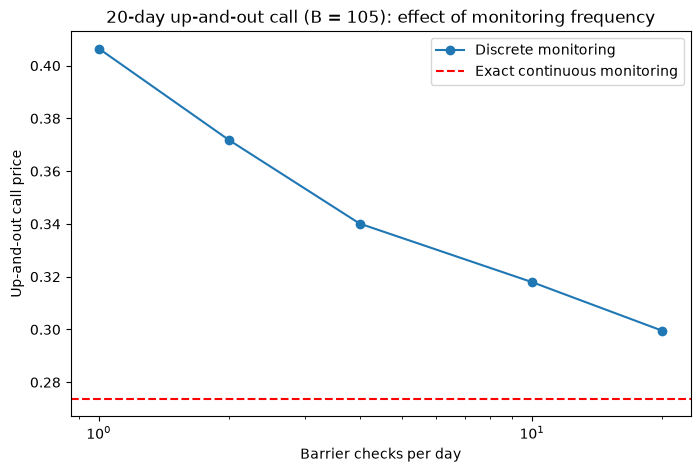

In [19]:
plt.figure(figsize=(8, 5))
plt.plot(study["checks per day"], study["price"], "o-", label="Discrete monitoring")
plt.axhline(exact_continuous, color="red", linestyle="--", label="Exact continuous monitoring")
plt.xscale("log")
plt.xlabel("Barrier checks per day")
plt.ylabel("Up-and-out call price")
plt.title("20-day up-and-out call (B = 105): effect of monitoring frequency")
plt.legend()
plt.savefig("../outputs/05_discrete_monitoring.png", dpi=150, bbox_inches="tight")
plt.show()

### Interpretation

- **Discrete monitoring overprices knock-out options, and the error is a bias, not noise.** At half-day steps the price is 0.098 too high, while its standard error is only 0.003. More paths would not help.
- **A finer grid converges slowly.** Halving the step from one day to half a day only reduces the error from 48% to 36%, roughly in proportion to the square root of the step length.
- **The barrier shift fixes most of it for free.** With half-day steps the error falls from +36% to about −1%, which is within simulation noise; with daily steps it falls from +48% to −5%. No extra computing time is needed.

> **Takeaway:** for a short-dated barrier option with the barrier close to the current price, how the barrier is monitored matters far more than the number of paths. A desk must know the monitoring rule in the contract, and should correct for it instead of relying on a finer grid.

### Greeks

**Purpose.** A Greek measures how the option price changes when one input changes. Here they are estimated by **finite differences**: change one input slightly, price the option again, and take the difference.

$$\Delta \approx \frac{V(S_0+h) - V(S_0-h)}{2h}, \qquad \Gamma \approx \frac{V(S_0+h) - 2V(S_0) + V(S_0-h)}{h^2}$$

Every re-pricing uses the **same seed** (common random numbers). A small change in an input moves the price by much less than the simulation error, so with different random numbers the noise would swamp the signal. With the same random numbers the noise cancels in the difference. The Black-Scholes formulas give the exact values for comparison.

In [20]:
from scipy.stats import norm

greeks = price_option(S0, K, expiry_days, r, sigma, "call", seed=seed, compute_greeks=True)["greeks"]

d1 = (np.log(S0 / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
d2 = d1 - sigma * np.sqrt(T)
bs_greeks = {
    "delta": norm.cdf(d1),
    "gamma": norm.pdf(d1) / (S0 * sigma * np.sqrt(T)),
    "vega": S0 * norm.pdf(d1) * np.sqrt(T) / 100,                                   # per 1 volatility point
    "theta": (-S0 * norm.pdf(d1) * sigma / (2 * np.sqrt(T))
              - r * K * np.exp(-r * T) * norm.cdf(d2)) / TRADING_DAYS,              # per trading day
    "rho": K * T * np.exp(-r * T) * norm.cdf(d2) / 100,                             # per 1 interest-rate point
}

greeks_table = pd.DataFrame({"Monte Carlo": greeks, "Black-Scholes": bs_greeks}).round(4)
greeks_table

,Monte Carlo,Black-Scholes
delta,0.6374,0.6368
gamma,0.0185,0.0188
vega,0.3774,0.3752
theta,-0.0290,-0.0255
rho,0.5328,0.5323


**Reading the table.**

| Greek | Value | Meaning |
|---|---|---|
| Delta | 0.64 | If the stock rises by 1, the call rises by about 0.64 |
| Gamma | 0.019 | Delta itself rises by about 0.019 for each rise of 1 in the stock |
| Vega | 0.38 | If volatility rises by one point (20% → 21%), the call rises by about 0.38 |
| Theta | −0.03 | The call loses about 0.03 of value per trading day |
| Rho | 0.53 | If the interest rate rises by one point (5% → 6%), the call rises by about 0.53 |

- **Delta, gamma, vega and rho agree with Black-Scholes to within 2%.**
- **Theta is the least accurate** (−0.029 against −0.026). Changing the expiry by one day changes the number of time steps, so the random numbers are no longer the same and the noise does not cancel.

> **Takeaway:** the engine gives risk measures as well as prices, provided the same random numbers are reused for every re-pricing.

## 11. Validation Summary & Conclusion

**Purpose.** Collect every check in one table, then summarise the findings and the limitations. Each row compares a simulated result with a value known from theory.

In [ ]:
validation = pd.DataFrame([
    {"Test": "Mean S_T = S0*e^(rT)", "Expected": S0 * np.exp(r * T), "Result": paths[:, -1].mean()},
    {"Test": "European call vs Black-Scholes", "Expected": bs_call, "Result": mc_call["price"]},
    {"Test": "European put vs Black-Scholes", "Expected": bs_put, "Result": mc_put["price"]},
    {"Test": "Put-call parity: C - P", "Expected": S0 - K * np.exp(-r * T), "Result": mc_call["price"] - mc_put["price"]},
    {"Test": "In-out parity (up, B=120)", "Expected": mc_call["price"],
     "Result": barrier_parity_table.loc[0, "In + Out"]},
    {"Test": "In-out parity (down, B=90)", "Expected": mc_call["price"],
     "Result": barrier_parity_table.loc[1, "In + Out"]},
    {"Test": "American call = European call", "Expected": mc_call["price"], "Result": american_call["price"]},
    {"Test": "Delta vs N(d1)", "Expected": bs_greeks["delta"], "Result": greeks["delta"]},
])
validation["Difference"] = validation["Result"] - validation["Expected"]
validation["Relative error"] = (validation["Difference"] / validation["Expected"]).map("{:.2%}".format)
validation.round(4)

,Test,Expected,Result,Difference,Relative error
0,Mean S_T = S0*e^(rT),105.1271,105.1672,0.0401,0.04%
1,European call vs Black-Scholes,10.4506,10.4829,0.0323,0.31%
2,European put vs Black-Scholes,5.5735,5.5676,-0.0059,-0.11%
3,Put-call parity: C - P,4.8771,4.9152,0.0382,0.78%
4,"In-out parity (up, B=120)",10.4829,10.4829,0.0000,0.00%
5,"In-out parity (down, B=90)",10.4829,10.4829,0.0000,0.00%
6,American call = European call,10.4829,10.4812,-0.0017,-0.02%
7,Delta vs N(d1),0.6368,0.6374,0.0006,0.10%


: 

**Reading the table.** All eight checks agree to within 1%. The two in-out parity rows are exact by construction. The largest relative error (0.78%, put-call parity) is the sampling error of the average final price, as explained in Section 4.

### Conclusion

**Main findings**

1. **The engine is correct.** Simulated European prices match Black-Scholes to within 0.3%, inside the 95% confidence interval at every strike tested, and eight independent checks agree to within 1%.
2. **The accuracy is known, and it costs paths.** The standard error falls with $\sqrt{N}$: 100,000 paths price a 10.48 call to about ±0.09 (95%) in about half a second. Antithetic variates cut the standard error by 29%, equivalent to about twice as many paths.
3. **Path-dependent options are cheaper.** The Asian call costs 45% less than the European call because averaging reduces volatility. An up-and-out call with a barrier at 120 is worth 1.32 of the European call's 10.48.
4. **Early exercise matters for puts, not calls.** The American put is worth 0.49 more than the European put (about 9%); the American call equals the European call when there are no dividends.
5. **Discrete monitoring is the largest error found.** For a 20-day up-and-out call with a barrier at 105, the project's half-day grid overprices by 36%. A simple barrier shift reduces the error to about 1% at no extra cost.
6. **Greeks:** finite differences with common random numbers reproduce the Black-Scholes delta, gamma, vega and rho to within 2%.

**Practical use.** The engine prices options that have no simple formula and reports an error bar with every price. A desk could use it to price Asian, barrier and American options in one consistent framework, to decide how many paths a required accuracy needs, and to recognise when the simulation set-up itself (such as barrier monitoring) biases the price.

**Limitations**

1. **Model:** constant volatility and interest rate, no jumps and no dividends.
2. **Barriers** are monitored only on the time grid; the correction was tested for one option only.
3. **American options:** the regression uses a simple quadratic, tends to price slightly low, and was not checked against an independent method such as a binomial tree.
4. **Theta** from finite differences is noisy.
5. **Inputs:** one set of test inputs; no market data and no calibration.

**Extensions**

- Check the American put against a binomial tree.
- Add control variates (for example the geometric Asian option) for further variance reduction.
- Replace GBM with a model that has stochastic volatility or jumps.